# Рисунок: кривые частот рёбер (a) и троек (b) при окне построения графа 40 и 80 кадров

In [1]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from wavelet_analysis import morlet_mean_power

### Инициализация путей

In [2]:
data_dir = Path(r"C:\Users\alvar\Documents\practice\test_repo_spectral_analysis")
sum_edges_dir = data_dir / "sum_edges_triples"
series_files = {
    ("mouse", 40): sum_edges_dir / "head_data" / "CA1_22_1D.npz",
    ("mouse", 80): sum_edges_dir / "sum_edges_triples_native_80_window.npz",
    ("llm",   40): sum_edges_dir / "sum_edges_triples_synthetic_data.npz",
    ("llm",   80): sum_edges_dir / "sum_edges_triples_synthetic_80_window.npz",
}

path_to_save_figure = data_dir / "figures" / "spectra" 
out_file = path_to_save_figure / "spectrum_data_different_windows.pdf"

### Определение параметров

In [3]:
fs = 20.0                            # частота кадров, Гц
freqs = np.logspace(-1, 1, 200)      # 0.1–10 Гц, логарифмическая сетка
normalize = "zscore"                 # "zscore" — ряд делится на std (сравнение формы спектров),
                                     # "none"   — абсолютная мощность, как в get_cwt


# Цвет — источник данных, тип линии — длина окна
colors = {"mouse": "#1f5fa8", "llm": "#d9711a"}
source_labels = {"mouse": "Mouse, CA1_22_1D", "llm": "LLM (Qwen2.5-1.5B)"}
linestyles = {40: "-", 80: "--"}
# ---------------------------------------------------------------------

CM = 1 / 2.54
plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "pdf.fonttype": 42,
    "axes.spines.top": False, "axes.spines.right": False,
})

### Непрерывное вейвлет-преобразование и расчет средней мощности

In [4]:
spectra = {}                          # (kind, source, window) -> средняя мощность
for (source, window), path in series_files.items():
    if not os.path.exists(path):
        print(f"Нет файла, пропускаю: {path}")
        continue
    with np.load(path) as z:
        for kind in ("edges", "triples"):
            result = morlet_mean_power(z[f"sum_{kind}"], frequencies=freqs, fs=fs, w=6.0, normalize=normalize)
            spectra[(kind, source, window)] = result

### Построение рисунка

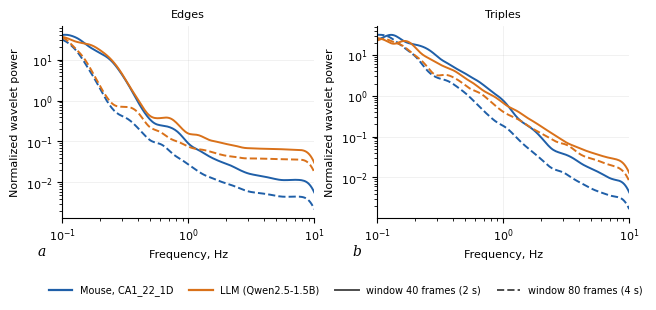

: 

In [ ]:
fig = plt.figure(figsize=(16 * CM, 7.6 * CM))
gs = fig.add_gridspec(3, 2, height_ratios=[1.0, 0.09, 0.08],
                      left=0.08, right=0.98, top=0.93, bottom=0.02,
                      wspace=0.25, hspace=0.32)
axs = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])]

for ax, kind, title in [(axs[0], "edges", "Edges"), (axs[1], "triples", "Triples")]:
    for source in colors:
        for window in linestyles:
            key = (kind, source, window)
            if key in spectra:
                ax.plot(freqs, spectra[key], color=colors[source],
                        ls=linestyles[window], lw=1.4)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(freqs[0], freqs[-1])
    ax.set_xlabel("Frequency, Hz")
    ax.set_ylabel("Normalized wavelet power" if normalize == "zscore" else "Mean wavelet power")
    ax.set_title(title)
    ax.grid(True, which="major", alpha=0.25, lw=0.5)

# буквы a, b в левом нижнем углу под панелями
for col, letter in enumerate("ab"):
    lax = fig.add_subplot(gs[1, col]); lax.axis("off")
    lax.text(-0.10, 0.0, letter, transform=lax.transAxes, fontsize=10,
             style="italic", family="serif", ha="left", va="bottom")

# компактная легенда в одну строку под рисунком: цвет — источник, линия — окно
handles = ([Line2D([], [], color=colors[s], lw=1.6, label=source_labels[s]) for s in colors] +
           [Line2D([], [], color="0.3", lw=1.4, ls=linestyles[w],
                   label=f"window {w} frames ({w / fs:g} s)") for w in linestyles])
leg_ax = fig.add_subplot(gs[2, :]); leg_ax.axis("off")
leg_ax.legend(handles=handles, loc="center", ncol=4, frameon=False,
              handlelength=2.4, columnspacing=1.6)

if out_file is not None:
    fig.savefig(out_file, dpi=300)
    fig.savefig(out_file.with_suffix(".png"), dpi=300)
plt.show()
